# Evaluation: does the twin find what was planted?

Freshly generated synthetic users (4 plan personas, 30 varied people, 10 pure-noise users,
90 days each) are run through **the same code as production**: features, pattern discovery,
predictions, time-of-day rhythm, traits and recommendations. They are then scored against
the ground truth planted in the data.

Plan targets: pattern recall ≥ 80% in the top 5; 0–1 false insights on noise users; a
learning curve that beats the "7-day mean" baseline; recommendation acceptance that rises
with feedback; extraction precision and recall on 50 hand-labelled chat messages.

Every chart is also saved to `docs/figures/` (PNG) for the report.

In [1]:
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import pandas as pd

from app.ml.evaluate import run

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": "#52514e",
        "xtick.color": "#898781",
        "ytick.color": "#898781",
        "font.size": 10,
    }
)
TWIN, BASE = "#2a78d6", "#d54810"  # validated pair (dataviz validator, white surface)
NEUTRAL, INK, MUTED = "#a8a69f", "#52514e", "#898781"
FIGS = Path.cwd().parents[1] / "docs" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    """Save a figure for the report (white background, 2x resolution)."""
    fig.savefig(FIGS / f"{name}.png", dpi=200, bbox_inches="tight", facecolor="white")


r = run(n_generated=30, n_noise=10)
p = r["patterns"]
print(f"Users: {r['users']['total']} ({r['users']['noise']} pure noise) | run time {r['seconds']}s")
print(f"Pattern recall@5: {p['recall_at_5']:.0%} of {p['planted_in_scope']} planted patterns")
print(
    f"False insights on noise users: max {p['false_insights_max']}, mean {p['false_insights_mean']}"
)
print(
    f"Task completion AUC: {r['tasks']['auc']}  |  chronotype accuracy: "
    f"{r['traits']['chronotype_accuracy']:.0%}  |  "
    f"optimism error: {r['traits']['optimism_abs_error']}"
)

Users: 44 (11 pure noise) | run time 121.8s
Pattern recall@5: 76% of 67 planted patterns
False insights on noise users: max 1, mean 0.09
Task completion AUC: 0.598  |  chronotype accuracy: 70%  |  optimism error: 0.015


## 1. Learning curve: twin vs the plan's baseline

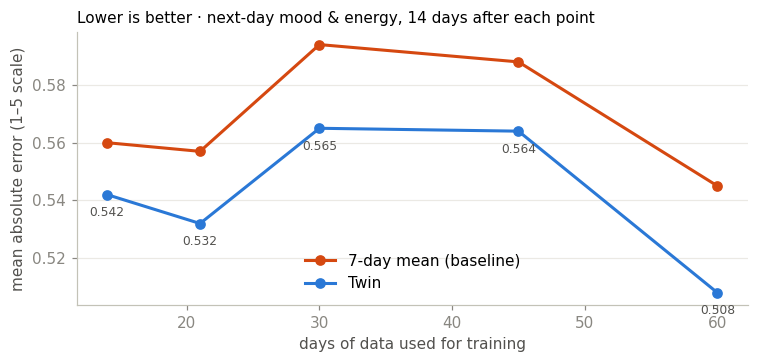

,twin_mae,baseline_mae,n,improvement
days of data,,,,
14,0.542,0.560,864.0,+3.2%
21,0.532,0.557,856.0,+4.5%
30,0.565,0.594,870.0,+4.9%
45,0.564,0.588,872.0,+4.1%
60,0.508,0.545,866.0,+6.8%


In [2]:
lc = pd.DataFrame(r["learning_curve"]).T
lc.index.name = "days of data"
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(
    lc.index, lc["baseline_mae"], color=BASE, lw=2, marker="o", ms=6, label="7-day mean (baseline)"
)
ax.plot(lc.index, lc["twin_mae"], color=TWIN, lw=2, marker="o", ms=6, label="Twin")
for x, y in zip(lc.index, lc["twin_mae"], strict=False):
    ax.annotate(
        f"{y:.3f}",
        (x, y),
        textcoords="offset points",
        xytext=(0, -14),
        ha="center",
        fontsize=8,
        color="#52514e",
    )
ax.set_xlabel("days of data used for training")
ax.set_ylabel("mean absolute error (1–5 scale)")
ax.grid(axis="y", color="#ebe9e4")
ax.legend(frameon=False)
ax.set_title(
    "Lower is better · next-day mood & energy, 14 days after each point", loc="left", fontsize=10
)
plt.tight_layout()
save(fig, "learning_curve")
plt.show()
lc.assign(improvement=lambda d: (1 - d.twin_mae / d.baseline_mae).map("{:+.1%}".format))

## 2. Pattern recall by planted pattern type

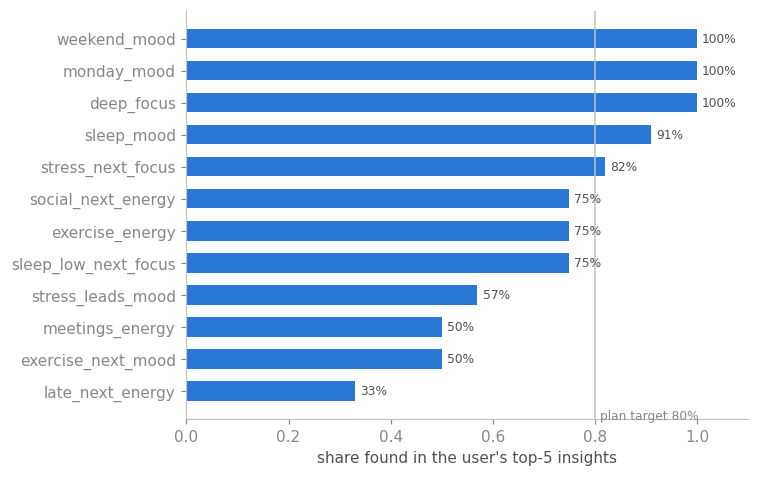

In [3]:
rec = pd.Series(p["recall_by_pattern"]).sort_values()
fig, ax = plt.subplots(figsize=(7, 0.32 * len(rec) + 0.6))
ax.barh(rec.index, rec.values, color=TWIN, height=0.6)
for i, v in enumerate(rec.values):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=8, color="#52514e")
ax.axvline(0.8, color="#c3c2b7", lw=1)
ax.text(0.81, -0.9, "plan target 80%", fontsize=8, color="#898781")
ax.set_xlim(0, 1.1)
ax.set_xlabel("share found in the user's top-5 insights")
plt.tight_layout()
save(fig, "pattern_recall")
plt.show()

Patterns targeting **stress** are not mined as insights (the plan's insight targets are mood,
energy, focus and completion); they surface through the *stress triggers* trait instead.

## 3. Noise users: false insights

In [4]:
pd.Series(p["false_insights"], name="insights found").to_frame().T

,noise,noise01,noise02,noise03,noise04,noise05,noise06,noise07,noise08,noise09,noise10
insights found,0,0,1,0,0,0,0,0,0,0,0


**Reading this:** recall shows the method finds most planted links without being told where
to look. The noise users show it doesn't invent links (Benjamini–Hochberg keeps the
false-discovery rate low; the plan allows 0–1). The learning curve shows the twin beats the
naive baseline at every amount of data, by learning only when a pattern is reliable (models
must beat the user's 4-week norm in walk-forward validation, otherwise it falls back to it).

## 4. Task completion and traits

The completion classifier predicts whether a planned task gets done. Synthetic completion is
mostly random by design, so a modest AUC is the honest result: the twin falls back to the
user's completion rate unless a model beats it in validation.

In [5]:
t, tr = r["tasks"], r["traits"]
pd.Series(
    {
        "completion AUC": t["auc"],
        "tasks scored": t["n_tasks"],
        "chronotype correct": f"{tr['chronotype_accuracy']:.0%}",
        "optimism error": tr["optimism_abs_error"],
    },
    name="value",
).to_frame()

,value
completion AUC,0.598
tasks scored,1168
chronotype correct,70%
optimism error,0.015


## 5. Time of day: the daily rhythm

Users who check in more than once a day get a per-slot forecast (morning / afternoon /
evening). Scored on held-out slot check-ins: the forecast with the learned rhythm against the
same forecast without it (daily value only).

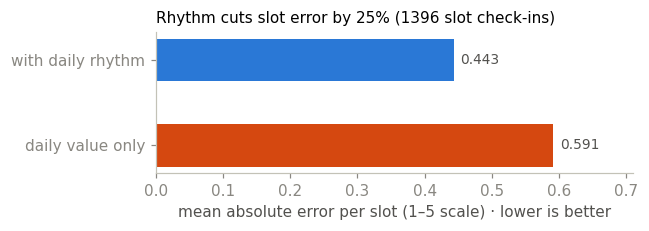

Best energy slot identified: 100% | rhythm statements found and right: 100% | noise users, max statements: 0


In [6]:
tod = r["time_of_day"]
vals = [tod["slot_mae_without"], tod["slot_mae_with_rhythm"]]
fig, ax = plt.subplots(figsize=(6, 2.2))
ax.barh(["daily value only", "with daily rhythm"], vals, color=[BASE, TWIN], height=0.5)
for i, v in enumerate(vals):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=9, color=INK)
ax.set_xlim(0, max(vals) * 1.2)
ax.set_xlabel("mean absolute error per slot (1–5 scale) · lower is better")
ax.set_title(
    f"Rhythm cuts slot error by {tod['slot_improvement']:.0%} "
    f"({tod['n_slot_checks']} slot check-ins)",
    loc="left",
    fontsize=10,
)
plt.tight_layout()
save(fig, "time_of_day")
plt.show()
print(
    f"Best energy slot identified: {tod['best_slot_accuracy']:.0%} | rhythm statements "
    f"found and right: {tod['statement_recall']:.0%} | noise users, max statements: "
    f"{tod['false_statements_max']}"
)

## 6. Adaptation: do 👍 / 👎 improve the suggestions?

Simulated users with hidden tastes rate three suggestions a day for four weeks. Acceptance =
share of shown suggestions the user likes. *Stable*: week 1 against week 4. *Tastes change*:
the hidden tastes flip after two weeks; last week's acceptance. "No learning" ranks by
relevance only and is the control.

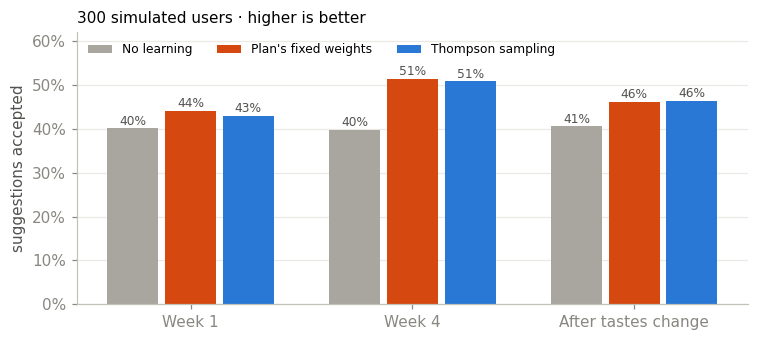

,week1_acceptance,week4_acceptance,after_change_acceptance
No learning,40.1%,39.8%,40.6%
Plan's fixed weights,44.1%,51.4%,46.2%
Thompson sampling,43.0%,50.8%,46.4%


In [7]:
ad = r["adaptation"]["policies"]
names = {
    "relevance": "No learning",
    "weights": "Plan's fixed weights",
    "thompson": "Thompson sampling",
}
colors = {"relevance": NEUTRAL, "weights": BASE, "thompson": TWIN}
groups = [
    ("week1_acceptance", "Week 1"),
    ("week4_acceptance", "Week 4"),
    ("after_change_acceptance", "After tastes change"),
]
fig, ax = plt.subplots(figsize=(7, 3.2))
w = 0.26
for j, (pol, label) in enumerate(names.items()):
    xs = [g + (j - 1) * w for g in range(len(groups))]
    ys = [ad[pol][k] for k, _ in groups]
    ax.bar(xs, ys, width=w - 0.03, color=colors[pol], label=label)
    for x, y in zip(xs, ys, strict=True):
        ax.text(x, y + 0.008, f"{y:.0%}", ha="center", fontsize=8, color=INK)
ax.set_xticks(range(len(groups)), [g for _, g in groups])
ax.set_ylim(0, 0.62)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("suggestions accepted")
ax.grid(axis="y", color="#ebe9e4")
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3, loc="upper left", fontsize=8)
ax.set_title(
    f"{r['adaptation']['users']} simulated users · higher is better", loc="left", fontsize=10
)
plt.tight_layout()
save(fig, "adaptation")
plt.show()
pd.DataFrame(ad).T.rename(index=names).map("{:.1%}".format)

**Reading this:** feedback lifts acceptance from about 44% to 51% in four weeks, while the
no-learning control stays at 40%. Thompson sampling (with feedback fading by 5% a day) is
*as good as* the plan's simple fixed-weight rule, not better; without the fading it did worse
after tastes changed. It stays the default because it also explores kinds of advice the user
has not rated yet.

## 7. Extraction accuracy (50 hand-labelled chat messages)

`python -m app.ml.extraction_eval --provider configured` scores the real LLM (OpenAI) against
`backend/evals/extraction_cases.json`; `--provider fake` scores the offline regex stand-in used
in tests. A fact counts as correct only when its value matches the label (durations within 15%).

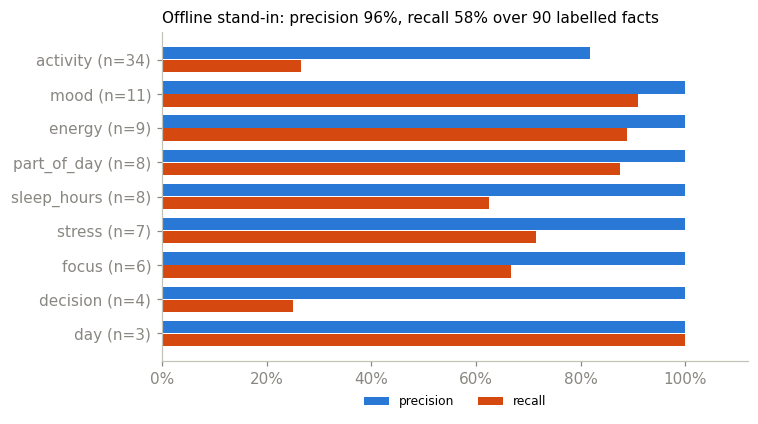

,precision,recall,n
Offline stand-in,0.963,0.578,90.0


In [8]:
import json

runs = {}
for name in ("configured", "fake"):
    f = Path.cwd().parent / "data" / f"extraction_eval_{name}.json"
    if f.exists():
        runs["OpenAI" if name == "configured" else "Offline stand-in"] = json.loads(
            f.read_text("utf-8")
        )
if not runs:
    print("Run `python -m app.ml.extraction_eval` first.")
else:
    label, ev = next(iter(runs.items()))  # the real LLM when it has been run
    pf = pd.DataFrame(ev["per_field"]).T.sort_values("n")
    fig, ax = plt.subplots(figsize=(7, 0.34 * len(pf) + 0.9))
    y = range(len(pf))
    ax.barh([i + 0.19 for i in y], pf["precision"], height=0.36, color=TWIN, label="precision")
    ax.barh([i - 0.19 for i in y], pf["recall"], height=0.36, color=BASE, label="recall")
    ax.set_yticks(list(y), [f"{k} (n={int(n)})" for k, n in pf["n"].items()])
    ax.set_xlim(0, 1.12)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.07), fontsize=8)
    o = ev["overall"]
    ax.set_title(
        f"{label}: precision {o['precision']:.0%}, recall {o['recall']:.0%} "
        f"over {o['n']} labelled facts",
        loc="left",
        fontsize=10,
    )
    plt.tight_layout()
    save(fig, "extraction")
    plt.show()
    display(pd.DataFrame({k: v["overall"] for k, v in runs.items()}).T)

## Summary

In [9]:
lc_last = r["learning_curve"][max(r["learning_curve"], key=int)]
th = r["adaptation"]["policies"]["thompson"]
pd.DataFrame(
    [
        ("Pattern recall (top 5)", "≥ 80%", f"{p['recall_at_5']:.0%}"),
        ("False insights, noise users", "0–1", f"max {p['false_insights_max']}"),
        (
            "Twin vs 7-day mean (60 days)",
            "beats it",
            f"{lc_last['twin_mae'] / lc_last['baseline_mae'] - 1:+.0%} error",
        ),
        ("Task completion AUC", "report", f"{r['tasks']['auc']}"),
        ("Time-of-day slot error vs no rhythm", "report", f"{-tod['slot_improvement']:+.0%}"),
        (
            "Acceptance week 1 → week 4",
            "rises",
            f"{th['week1_acceptance']:.0%} → {th['week4_acceptance']:.0%}",
        ),
    ]
    + [
        (
            "Extraction precision / recall",
            "report",
            f"{v['overall']['precision']:.0%} / {v['overall']['recall']:.0%} ({k})",
        )
        for k, v in runs.items()
    ],
    columns=["metric", "plan target", "result"],
).set_index("metric")

,plan target,result
metric,,
Pattern recall (top 5),≥ 80%,76%
"False insights, noise users",0–1,max 1
Twin vs 7-day mean (60 days),beats it,-7% error
Task completion AUC,report,0.598
Time-of-day slot error vs no rhythm,report,-25%
Acceptance week 1 → week 4,rises,43% → 51%
Extraction precision / recall,report,96% / 58% (Offline stand-in)
